# Notebook 01 — Data Understanding and Exploratory Data Analysis

**Project:** Bank Marketing Subscription Prediction Using Machine Learning

This notebook loads the UCI Bank Marketing dataset (Moro, Rita, & Cortez, 2014; https://doi.org/10.24432/C5K306), checks its quality and explores it with five figures that guide the modelling decisions. Run the notebooks in the order 01 → 05 and execute all cells from the top (*Restart* → *Run All*).

## 1. Setup

This section imports the libraries and project modules and applies the common figure style used in all notebooks.

In [1]:
# Make the project's src/ package importable (notebooks live in notebooks/)
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

# Hide FutureWarnings from libraries so that the outputs stay readable
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Project modules: figure style, paths, feature lists and data helpers
from src.plot_style import apply_style, BLUE, ORANGE, GREY, DIVERGING_CMAP
from src.config import FIGURES_DIR, RESULTS_DIR, NUMERIC_FEATURES
from src.data_loader import load_raw_data, data_quality_report, summarize_dataset

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Output folders for figures and result tables
FIGURES_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

## 2. Data Loading

This section loads `data/raw/bank-full.csv` (downloaded automatically from UCI if missing) and checks its size against the official documentation (45,211 rows, 16 inputs + target).

In [2]:
# Load the raw dataset (separator ";")
df = load_raw_data()

# Check the dataset dimensions against the documented size
print("Dataset shape:", df.shape)
assert df.shape == (45211, 17), "Unexpected dataset size - check the downloaded file!"

# Display the first five records
df.head()

Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 3. Column Description

The table summarises the meaning of each column according to the official `bank-names.txt` file.

| # | Column | Type | Meaning |
|---|--------|------|---------|
| 1 | age | numeric | Age of the client (years) |
| 2 | job | categorical | Type of job (12 values incl. `unknown`) |
| 3 | marital | categorical | Marital status: married, single, divorced (incl. widowed) |
| 4 | education | categorical | primary, secondary, tertiary, unknown |
| 5 | default | binary | Has credit in default? |
| 6 | balance | numeric | Average yearly balance (euros) |
| 7 | housing | binary | Has a housing loan? |
| 8 | loan | binary | Has a personal loan? |
| 9 | contact | categorical | Contact type: cellular, telephone, unknown |
| 10 | day | numeric | Last contact day of the month |
| 11 | month | categorical | Last contact month of the year |
| 12 | **duration** | numeric | Last call duration in seconds — **known only after the call (leakage, Section 6)** |
| 13 | campaign | numeric | Number of contacts during this campaign (incl. the last) |
| 14 | pdays | numeric | Days since the last contact in a previous campaign (**−1 = never contacted**) |
| 15 | previous | numeric | Number of contacts before this campaign |
| 16 | poutcome | categorical | Outcome of the previous campaign: success, failure, other, unknown |
| 17 | **y (target)** | binary | Has the client subscribed to a term deposit? **yes / no** |

In [3]:
# Data types as loaded by pandas: 7 integer columns and 10 text (categorical) columns
pd.DataFrame({"dtype": df.dtypes.astype(str), "example": df.iloc[0]})

,dtype,example
age,int64,58
job,str,management
marital,str,married
education,str,tertiary
default,str,no
balance,int64,2143
housing,str,yes
loan,str,no
contact,str,unknown
day,int64,5


## 4. Data Quality

### 4.1 Missing Values and "unknown" Placeholders

This section counts empty cells (NaN) and the text `"unknown"`, which the dataset uses as a hidden missing value.

In [4]:
# Count NaN and "unknown" values and the number of distinct values per column
quality = data_quality_report(df)
quality.to_csv(RESULTS_DIR / "data_quality.csv", index=False)
quality

,column,dtype,n_missing_NaN,n_unknown,pct_unknown,n_distinct
0,age,int64,0,0,0.00,77
1,job,categorical,0,288,0.64,12
2,marital,categorical,0,0,0.00,3
3,education,categorical,0,1857,4.11,4
4,default,categorical,0,0,0.00,2
5,balance,int64,0,0,0.00,7168
6,housing,categorical,0,0,0.00,2
7,loan,categorical,0,0,0.00,2
8,contact,categorical,0,13020,28.80,3
9,day,int64,0,0,0.00,31


**Interpretation.** No column contains NaN, but `"unknown"` appears in `poutcome` (≈82 %), `contact` (≈29 %), `education` (≈4 %) and `job` (<1 %). We keep `"unknown"` as its own category (Notebook 02), because deleting these rows would remove up to 82 % of the data and the placeholder can itself be informative.

### 4.2 Duplicate Records

This section checks whether any client record appears more than once.

In [5]:
# Count rows that are exact copies of an earlier row
n_duplicates = df.duplicated().sum()
print(f"Number of fully duplicated rows: {n_duplicates}")

Number of fully duplicated rows: 0


**Interpretation.** There are no duplicated rows, so no records need to be removed.

### 4.3 Summary Statistics of the Numeric Columns

This section describes the range and skewness of the numeric variables.

In [6]:
# Count, mean, standard deviation and quartiles of every numeric column
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


**Interpretation.** `balance`, `campaign`, `pdays`, `previous` and `duration` are strongly right-skewed (e.g. balance up to 102,127; previous up to 275), and `balance` can be negative. The median of `pdays` is −1, the code for *never contacted*. These observations motivate the outlier analysis and scaling in Notebook 02.

## 5. Exploratory Data Analysis

This section presents the five EDA figures. Groups are compared by their **subscription rate** (share of "yes") rather than raw counts because of the class imbalance; the dashed line marks the overall rate and *n* is the number of clients per group.

In [7]:
# Overall subscription rate (%), used as the reference line in Figures 2-4
is_yes = df["y"] == "yes"
OVERALL_RATE = is_yes.mean() * 100


def plot_subscription_rate(groups, order, tick_labels, title, xlabel, filename, figsize=(8, 4.3)):
    """Vertical bar chart of the subscription rate (%) per group, in the given order."""
    # Rate (%) and number of clients for every group, in the requested display order
    stats = is_yes.groupby(groups, observed=True).agg(rate="mean", n="size").reindex(order)
    stats["rate"] *= 100

    fig, ax = plt.subplots(figsize=figsize)
    x = np.arange(len(stats))
    ax.bar(x, stats["rate"], color=BLUE, width=0.62)
    ax.axhline(OVERALL_RATE, ls="--", color=GREY, lw=1.2, label=f"Overall rate = {OVERALL_RATE:.1f}%")

    # Direct labels: rate on the first line, group size on the second (white box keeps them readable over the line)
    for i, (rate, n) in enumerate(zip(stats["rate"], stats["n"])):
        ax.text(i, rate + stats["rate"].max() * 0.02, f"{rate:.1f}%\nn={n:,}", ha="center", va="bottom",
                fontsize=8.5, bbox=dict(facecolor="white", edgecolor="none", pad=1.0, alpha=0.9), zorder=4)

    ax.set_xticks(x, tick_labels)
    ax.set_ylim(0, stats["rate"].max() * 1.25)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Subscription rate (%)")
    ax.legend(loc="upper left")
    fig.savefig(FIGURES_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    return stats.round(1)

### Figure 1 — Target Distribution

This figure shows how many clients did and did not subscribe to a term deposit.

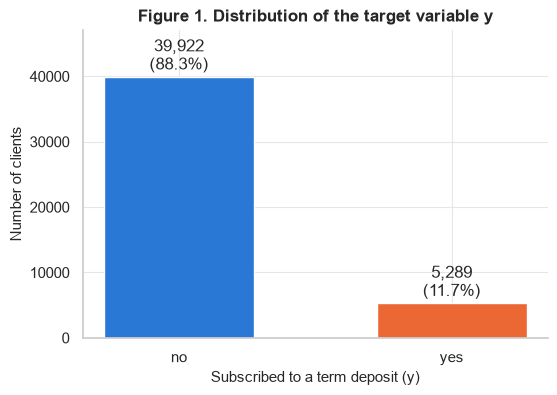

yes = 5,289 (11.70%), no = 39,922
Imbalance ratio (no : yes) = 7.55 : 1


In [8]:
# Number of clients per target class, in the order no / yes
summary = summarize_dataset(df)
counts = df["y"].value_counts().reindex(["no", "yes"])

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values, color=[BLUE, ORANGE], width=0.55)

# Label each bar with the count and the percentage of all clients
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, n + 400,
            f"{n:,}\n({100 * n / len(df):.1f}%)", ha="center", va="bottom")

ax.set_title("Figure 1. Distribution of the target variable y")
ax.set_xlabel("Subscribed to a term deposit (y)")
ax.set_ylabel("Number of clients")
ax.set_ylim(0, counts.max() * 1.18)
fig.savefig(FIGURES_DIR / "fig01_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# Imbalance ratio between the majority and the minority class
print(f"yes = {summary['n_yes']:,} ({summary['pct_yes']:.2f}%), no = {summary['n_no']:,}")
print(f"Imbalance ratio (no : yes) = {summary['n_no'] / summary['n_yes']:.2f} : 1")

**Figure 1.** Distribution of the target variable `y`.
*Interpretation:* Only 5,289 of 45,211 clients (11.7 %) subscribed, a 7.55 : 1 class imbalance; a model that always predicts "no" would already reach 88.3 % accuracy, so we use stratified splits, class weights and imbalance-aware metrics (ROC-AUC, precision, recall, F1) instead of accuracy alone.

### Figure 2 — Subscription Rate by Age Group

This figure shows how the subscription rate changes across six age groups.

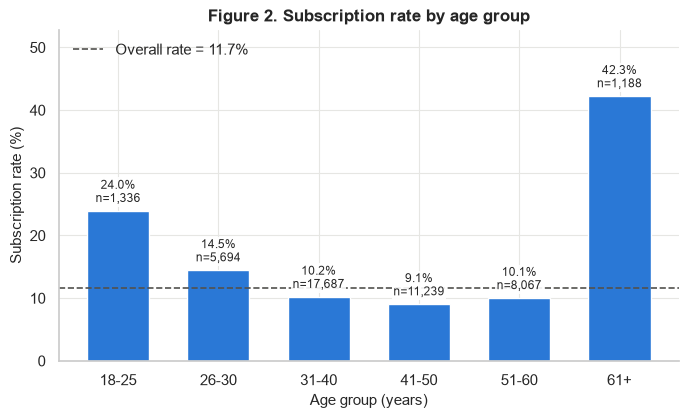

,rate,n
age,,
18-25,24.0,1336
26-30,14.5,5694
31-40,10.2,17687
41-50,9.1,11239
51-60,10.1,8067
61+,42.3,1188


In [9]:
# Group the clients into six age groups (the same bins are used in the error analysis of Notebook 05)
age_labels = ["18-25", "26-30", "31-40", "41-50", "51-60", "61+"]
age_groups = pd.cut(df["age"], bins=[17, 25, 30, 40, 50, 60, 100], labels=age_labels)

plot_subscription_rate(age_groups, order=age_labels, tick_labels=age_labels,
                       title="Figure 2. Subscription rate by age group",
                       xlabel="Age group (years)", filename="fig02_rate_by_age.png")

**Figure 2.** Subscription rate by age group.
*Interpretation:* The relationship is U-shaped: clients aged 61+ (42.3 %) and 18–25 (24.0 %) subscribe far more often than clients aged 31–60 (≈9–10 %), a non-linear effect that tree-based models can capture more easily than a linear model.

### Figure 3 — Subscription Rate by Previous Campaign Outcome

This figure relates the outcome of the previous marketing campaign (`poutcome`) to the subscription rate. First we check what the `unknown` category represents.

pdays     contacted before  never contacted
poutcome                                   
failure               4901                0
other                 1840                0
success               1511                0
unknown                  5            36954


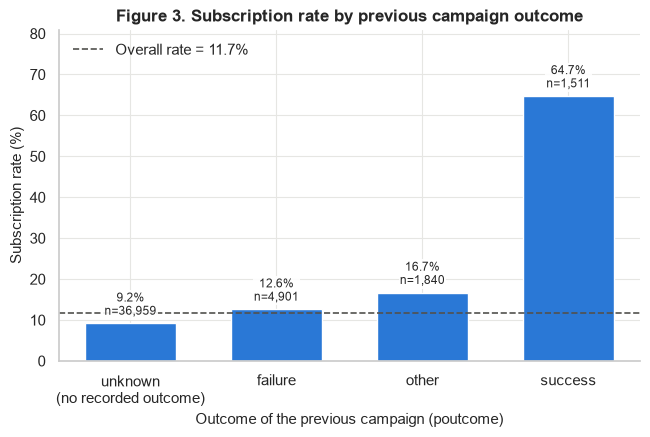

,rate,n
poutcome,,
unknown,9.2,36959
failure,12.6,4901
other,16.7,1840
success,64.7,1511


In [10]:
# "unknown" in poutcome: how many of these clients were never contacted before (pdays = -1)?
never_contacted = df["pdays"] == -1
print(pd.crosstab(df["poutcome"], never_contacted.map({True: "never contacted", False: "contacted before"})))

# Plot the categories from no information (unknown) to the most positive outcome (success)
poutcome_order = ["unknown", "failure", "other", "success"]
poutcome_labels = ["unknown\n(no recorded outcome)", "failure", "other", "success"]
plot_subscription_rate(df["poutcome"], order=poutcome_order, tick_labels=poutcome_labels,
                       title="Figure 3. Subscription rate by previous campaign outcome",
                       xlabel="Outcome of the previous campaign (poutcome)",
                       filename="fig03_rate_by_poutcome.png", figsize=(7.5, 4.3))

**Figure 3.** Subscription rate by previous campaign outcome.
*Interpretation:* Clients whose previous campaign was a success subscribe 64.7 % of the time (5.5× the overall rate), whereas `unknown` has the lowest rate (9.2 %); because 36,954 of the 36,959 `unknown` clients were never contacted before, `unknown` means "no previous campaign" rather than missing data and is therefore kept as a separate category.

### Figure 4 — Subscription Rate by Contact Month

This figure shows the subscription rate for each month of the last contact, in calendar order.

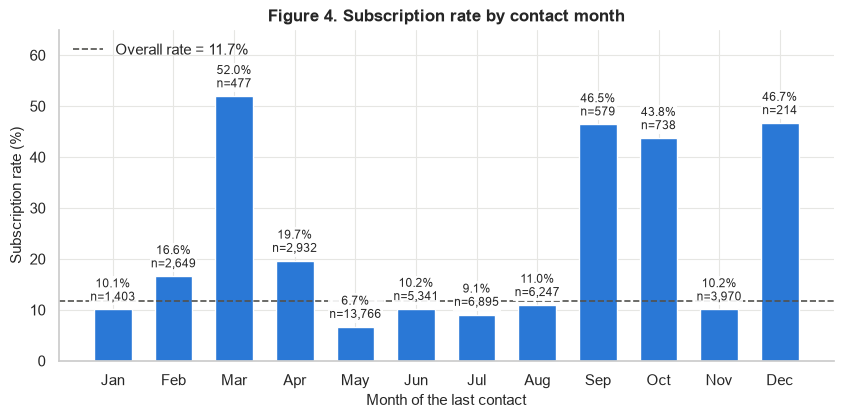

,rate,n
month,,
jan,10.1,1403
feb,16.6,2649
mar,52.0,477
apr,19.7,2932
may,6.7,13766
jun,10.2,5341
jul,9.1,6895
aug,11.0,6247
sep,46.5,579


In [11]:
# Calendar order (not alphabetical) and readable tick labels
month_order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
month_labels = [m.capitalize() for m in month_order]

plot_subscription_rate(df["month"], order=month_order, tick_labels=month_labels,
                       title="Figure 4. Subscription rate by contact month",
                       xlabel="Month of the last contact", filename="fig04_rate_by_month.png",
                       figsize=(10, 4.3))

**Figure 4.** Subscription rate by contact month.
*Interpretation:* May has by far the most contacts (13,766) but the lowest rate (6.7 %), while the rarely used months March, September, October and December reach 44–52 %; `month` therefore reflects the bank's campaign strategy as well as the calendar and is a strong predictor.

### Figure 5 — Correlation Heatmap of the Numeric Variables

This figure shows the Pearson correlation between all numeric variables and the target encoded as 1 = yes, 0 = no.

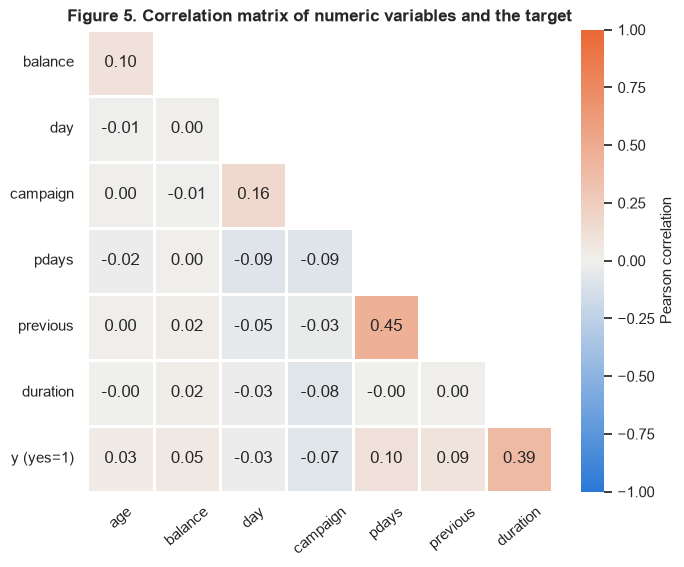

duration    0.395
pdays       0.104
previous    0.093
balance     0.053
age         0.025
day        -0.028
campaign   -0.073
Name: y (yes=1), dtype: float64

In [12]:
# Numeric variables (including duration, for the leakage check) and the binary target
numeric_with_target = df[NUMERIC_FEATURES + ["duration"]].assign(**{"y (yes=1)": is_yes.astype(int)})
corr = numeric_with_target.corr()

# Show each pair once: lower triangle without the diagonal (= 1), so the empty first row
# and last column are dropped
corr_pairs = corr.iloc[1:, :-1]
mask = np.triu(np.ones_like(corr_pairs, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr_pairs, mask=mask, annot=True, fmt=".2f", cmap=DIVERGING_CMAP, vmin=-1, vmax=1,
            linewidths=2, linecolor="white", cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Figure 5. Correlation matrix of numeric variables and the target")
ax.grid(False)
ax.tick_params(axis="x", rotation=40)
ax.tick_params(axis="y", rotation=0)
fig.savefig(FIGURES_DIR / "fig05_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# Correlation of every numeric variable with the target, strongest first
corr["y (yes=1)"].drop("y (yes=1)").sort_values(ascending=False).round(3)

**Figure 5.** Correlation matrix of the numeric variables and the target.
*Interpretation:* Linear correlations between the usable numeric features and the target are weak (|r| ≤ 0.10; e.g. pdays 0.10, campaign −0.07), the only notable input–input correlation is pdays–previous (0.45, too low to require removing a feature), and the strongest correlation is with `duration` (0.39), which is excluded because of leakage (Section 6).

## 6. Why `duration` Is Excluded (Data Leakage)

`duration` is the length of the last call, so it is only known **after** the call has ended, and a call of length 0 always ends in "no". Our goal is to decide **whom to call before calling**, and the UCI documentation itself recommends discarding this feature for a realistic model. It is therefore excluded from the main model; Notebook 04 shows in a secondary experiment how much it would inflate the scores.

In [13]:
# Median call duration (seconds) for subscribers and non-subscribers
df.groupby("y")["duration"].median().rename("median duration (s)")

y
no     164.0
yes    426.0
Name: median duration (s), dtype: float64

**Interpretation.** Subscribers' calls last about 2.6 times longer than non-subscribers' calls (median 426 s vs 164 s). Long calls are a *consequence* of an interested client, not information available in advance, which is exactly the definition of target leakage.

## 7. Summary of EDA Findings

| Finding | Consequence for modelling |
|---|---|
| 45,211 rows, 16 inputs (7 numeric, 9 categorical), binary target `y` | Binary classification |
| Strong imbalance: 11.7 % yes (Figure 1) | Stratified splits, class weights, ROC-AUC / F1 / recall instead of accuracy |
| No NaN, no duplicates; `"unknown"` in job, education, contact, poutcome | Keep `"unknown"` as a category; imputers kept for robustness (app inputs) |
| Skewed numeric features with extreme values | Standard scaling; outliers analysed (Notebook 02) but kept |
| `pdays = −1` is a code for *never contacted* | Add a `previously_contacted` flag (Notebook 02) |
| Strong signals: previous outcome (Figure 3), month (Figure 4), age with a U-shape (Figure 2) | Non-linear models are likely to help |
| Weak linear correlations among usable features (Figure 5) | Keep all features; combine them in flexible models |
| `duration` leaks the outcome (Section 6) | Excluded from the realistic model |